## Day 2-Street Orientation with OSMNx

In [ ]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

weight_by_length = False

In [31]:
places = {"Pogung" : "Sinduadi, Sleman, Yogyakarta",
          "Bantul" : "Bantul Regency, Yogyakarta"}

In [33]:
gdf = ox.geocoder.geocode_to_gdf(list(places.values()))
gdf

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((110.35101 -7.75984, 110.35111 -7.760...",110.351013,-7.771707,110.387198,-7.742941,32001526,relation,5615367,-7.758232,110.372737,boundary,administrative,16,0.220526,village,Sinduadi,"Sinduadi, Mlati, Sleman Regency, Special Regio..."
1,"POLYGON ((110.20385 -7.98321, 110.20413 -7.983...",110.203855,-8.028153,110.521311,-7.768021,32138443,relation,5615253,-7.898254,110.385553,boundary,administrative,12,0.457007,county,Bantul Regency,"Bantul Regency, Special Region of Yogyakarta, ..."


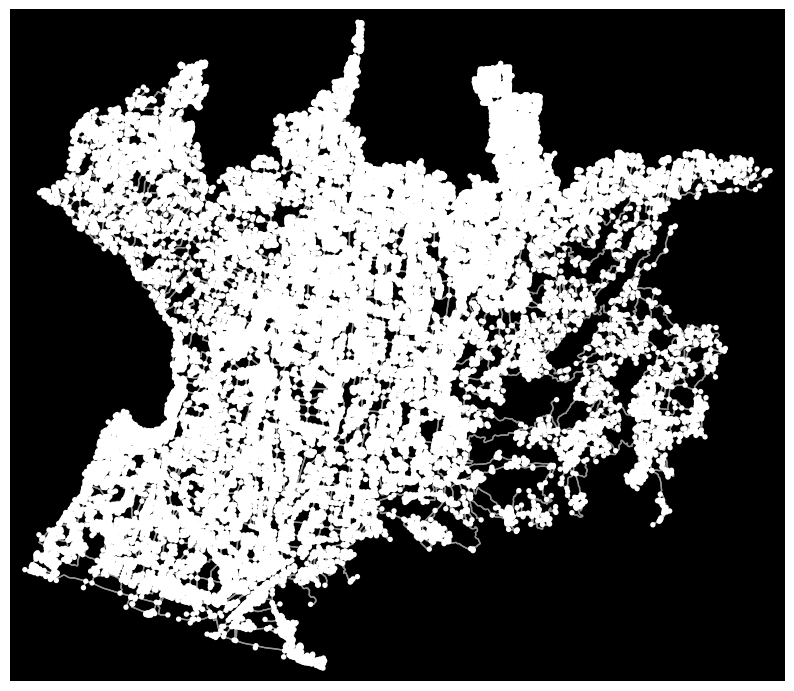

In [25]:
# For Bantul
G_bantul = ox.graph.graph_from_place(
    places["Bantul"], network_type="drive"
)  # or places["Bantul Regency"] depending on your dict

fig, ax = ox.plot_graph(
    G_bantul,
    figsize=(10, 10),
    node_size=15,
    node_color="w",
    edge_linewidth=1,
    edge_color="#999999",
    bgcolor="k",
)
plt.show()

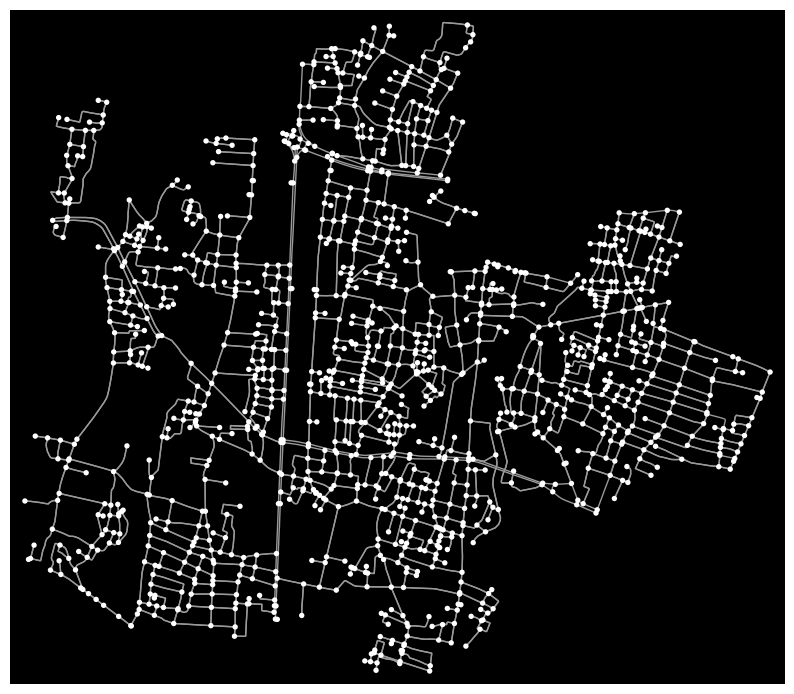

In [35]:
# For Pogung
G_p = ox.graph.graph_from_place(
    places["Pogung"], network_type="drive"
)  # or places["Bantul Regency"] depending on your dict

fig, ax = ox.plot_graph(
    G_p,
    figsize=(10, 10),
    node_size=15,
    node_color="w",
    edge_linewidth=1,
    edge_color="#999999",
    bgcolor="k",
)
plt.show()

2026-11-03 06:36:20 Bantul
2026-11-03 06:38:44 Pogung


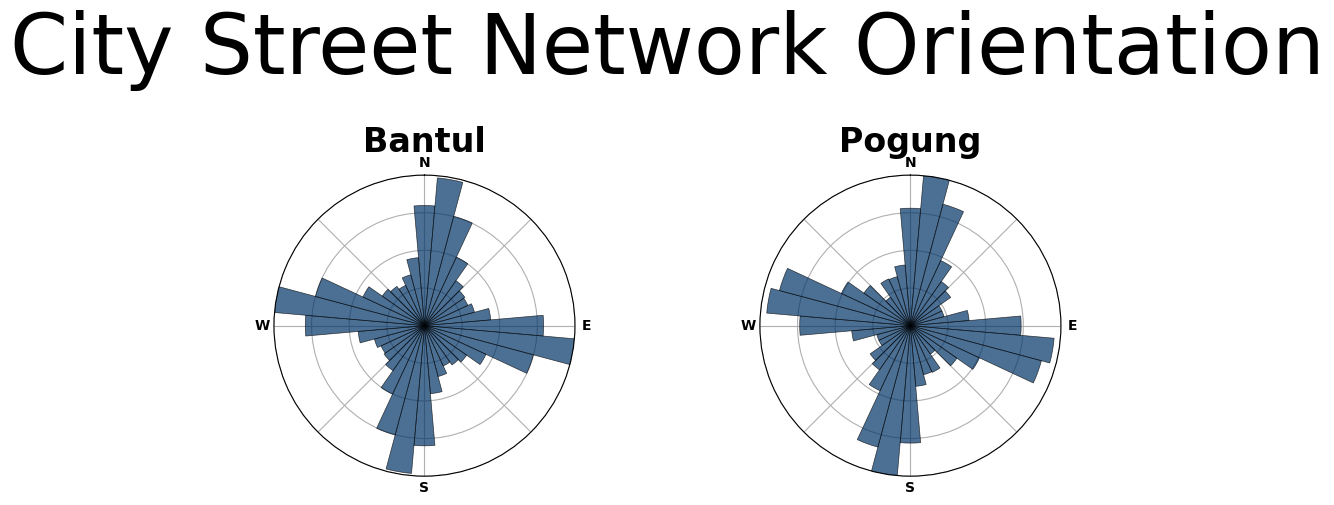

In [43]:
# create figure and axes
n = len(places)
ncols = int(np.ceil(np.sqrt(n)))
nrows = int(np.ceil(n / ncols))
figsize = (ncols * 5, nrows * 5)
fig, axes = plt.subplots(nrows, ncols, figsize=figsize, subplot_kw={"projection": "polar"})

# plot each city's polar histogram
for ax, place in zip(axes.flat, sorted(places.keys()), strict=False):
    print(ox.utils.ts(), place)

    # get undirected graphs with edge bearing attributes
    G = ox.graph.graph_from_place(places[place], network_type="drive")
    Gu = ox.bearing.add_edge_bearings(ox.convert.to_undirected(G))
    fig, ax = ox.plot.plot_orientation(Gu, ax=ax, title=place, area=True)

# add figure title and save image
suptitle_font = {
    "family": "DejaVu Sans",
    "fontsize": 60,
    "fontweight": "normal",
    "y": 1,
}
fig.suptitle("City Street Network Orientation", **suptitle_font)
fig.tight_layout()
fig.subplots_adjust(hspace=0.35)
#fig.savefig("images/street-orientations.png", facecolor="w", dpi=100, bbox_inches="tight")
#plt.close()
plt.show()

fig, ax = ox.plot_graph(
    G, 
    figsize=(10, 10), 
    node_size=15,          # Size of the intersection nodes (set to 0 to hide)
    node_color='w',        # Color of the nodes
    edge_linewidth=1,      # Width of the edge/street lines
    edge_color='#999999',  # Color of the edges
    bgcolor='k'            # Background color ('k' for black, 'w' for white)
)

plt.show()

#plot the graph but it displays the latest dataset not both

Bar Chart

In [47]:
G_p = ox.add_edge_bearings(G_p)

_, edges_gdf = ox.graph_to_gdfs(G_p, nodes=False)
bearings = edges_gdf["bearing"].dropna()

# 3. Plot the histogram
fig, ax = plt.subplots(figsize=(8, 5))
bearings.hist(bins=36, ax=ax, zorder=2, alpha=0.6, color="#003366", edgecolor="black")

ax.set_xlim(0, 360)
ax.set_xlabel("Bearing (Degrees)")
ax.set_ylabel("Frequency (Number of Edges)")
ax.set_title("Network Edge Bearings Distribution")

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

ValueError: too many values to unpack (expected 2)

In [ ]:
import osmnx as ox

# 1. Assume G is your graph and gdf is your GeoDataFrame containing the boundary polygon(s)
# Make sure both the graph and GeoDataFrame share the same Coordinate Reference System (CRS)
# e.g., gdf = gdf.to_crs(G.graph['crs'])

# 2. Extract a single Shapely Polygon or MultiPolygon from the GeoDataFrame
# (e.g., taking the geometry of the first row)
poly = gdf.geometry.unary_union  # Or gdf.iloc[0].geometry

# 3. Clip/truncate the graph using the polygon
G_clipped = ox.truncate.truncate_graph_polygon(
    G, 
    poly, 
    truncate_by_edge=False  # Set to True if you want to keep nodes outside 
                            # if at least one neighbor falls inside the boundary
)